# Population across Vienna’s districts


How did Vienna’s population change from 2002 to 2025, and which districts had the most residents in 2025? 

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

df = pd.read_csv("tab-5-1-2-bevoe.csv", sep=";", skiprows=3, dtype=str)

In [2]:
df.head()

,District,2002,2003,2004,2005,2006,2007,2008,2009,2010,...,2019,2020,2021,2022,2023,2024,2025,Unnamed: 25,Unnamed: 26,Unnamed: 27
0,1. Innere Stadt,17.630,17.541,17.384,17.294,17.285,17.147,16.976,16.623,16.525,...,16.306,16.047,15.867,15.700,16.620,16.538,16.281,NaN,NaN,NaN
1,2. Leopoldstadt,89.016,89.954,90.837,91.364,92.170,93.313,93.463,93.822,94.735,...,104.946,105.848,105.237,104.688,108.269,110.100,112.675,NaN,NaN,NaN
2,3. Landstraße,82.227,82.297,83.019,83.827,84.208,83.919,83.050,82.979,83.061,...,91.745,91.680,93.248,93.744,96.756,98.398,98.881,NaN,NaN,NaN
3,4. Wieden,28.975,29.348,29.394,29.573,30.126,30.189,30.262,30.348,30.331,...,33.263,33.212,33.075,33.007,33.633,33.155,33.444,NaN,NaN,NaN
4,5. Margareten,49.785,50.367,51.098,51.882,52.534,52.286,52.434,52.288,52.354,...,55.407,55.123,54.373,53.731,55.018,54.400,54.581,NaN,NaN,NaN


## Data Cleaning

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 87 entries, 0 to 86
Data columns (total 28 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   District     23 non-null     str  
 1   2002         23 non-null     str  
 2   2003         23 non-null     str  
 3   2004         23 non-null     str  
 4   2005         23 non-null     str  
 5   2006         23 non-null     str  
 6   2007         23 non-null     str  
 7   2008         23 non-null     str  
 8   2009         23 non-null     str  
 9   2010         23 non-null     str  
 10  2011         23 non-null     str  
 11  2012         23 non-null     str  
 12  2013         23 non-null     str  
 13  2014         23 non-null     str  
 14  2015         23 non-null     str  
 15  2016         23 non-null     str  
 16  2017         23 non-null     str  
 17  2018         23 non-null     str  
 18  2019         23 non-null     str  
 19  2020         23 non-null     str  
 20  2021         23 non-nul

In [4]:
# drop unnecessary columns 

df = df.drop(columns = ['Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27'])
df.isnull().sum()

District    64
2002        64
2003        64
2004        64
2005        64
2006        64
2007        64
2008        64
2009        64
2010        64
2011        64
2012        64
2013        64
2014        64
2015        64
2016        64
2017        64
2018        64
2019        64
2020        64
2021        64
2022        64
2023        64
2024        64
2025        64
dtype: int64

In [5]:
# drop empty rows 

df = df.dropna(how="all")
df.isnull().sum()

District    0
2002        0
2003        0
2004        0
2005        0
2006        0
2007        0
2008        0
2009        0
2010        0
2011        0
2012        0
2013        0
2014        0
2015        0
2016        0
2017        0
2018        0
2019        0
2020        0
2021        0
2022        0
2023        0
2024        0
2025        0
dtype: int64

In [6]:
# remove District number in district column  
df.rename(columns={"District": "district"})
df["District"] = (
    df["District"]
    .str.replace(r"^\s*\d+\.\s*", "", regex=True)
    .str.strip()
)


In [7]:
# Convert population values to integers and reshape the frame 

years = df.columns.drop("District")
for year in years:
    df[year] = (
        df[year]
        .astype(str)
        .str.replace(".", "", regex=False)
        .astype(int)
    )

df = df.melt(
    id_vars="District",
    var_name="year",
    value_name="population"
)

df["year"] = df["year"].astype(int)

In [8]:
df 

,District,year,population
0,Innere Stadt,2002,17630
1,Leopoldstadt,2002,89016
2,Landstraße,2002,82227
3,Wieden,2002,28975
4,Margareten,2002,49785
...,...,...,...
547,Döbling,2025,76074
548,Brigittenau,2025,86950
549,Floridsdorf,2025,189551
550,Donaustadt,2025,228158


In [9]:
print(f"\nDuplicate rows: {df.duplicated().sum()}")


Duplicate rows: 0


## How did Vienna’s population change?

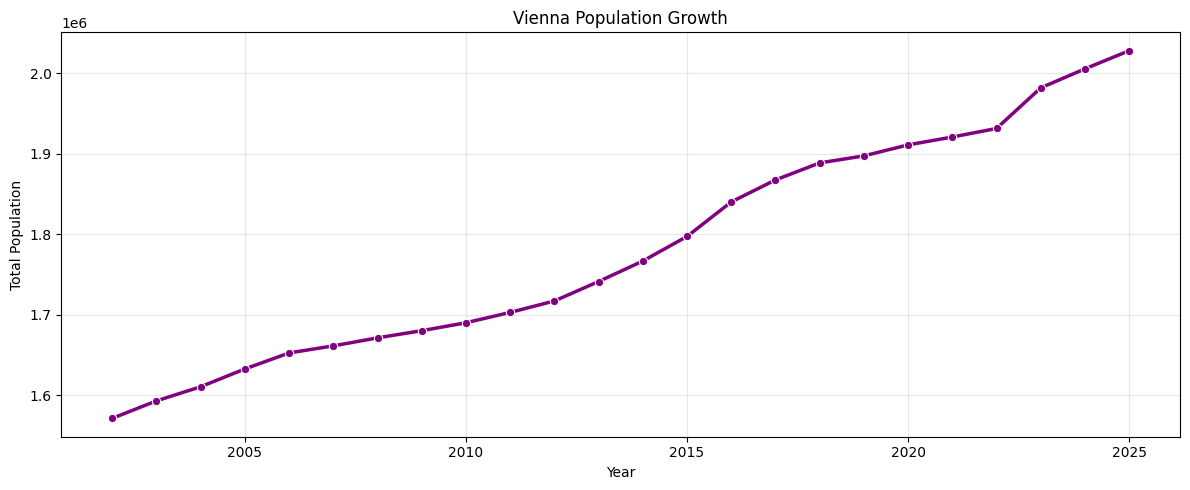

In [10]:
yearly_pop = df.groupby("year")["population"].sum().reset_index()

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=yearly_pop,
    x="year",
    y="population",
    color="purple",
    marker="o",
    linewidth=2.5
)

plt.title("Vienna Population Growth")
plt.xlabel("Year")
plt.ylabel("Total Population")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpetation:** Vienna grew from 1,571,123 residents in 2002 to 2,028,289 in 2025, an increase of about 29%.

## Which districts had the most residents in 2025?

In [11]:
# we keep only 2025 for further analysis 
latest_year = df["year"].max()
df = (df[df["year"] == latest_year].copy().sort_values(by="population", ascending=False))

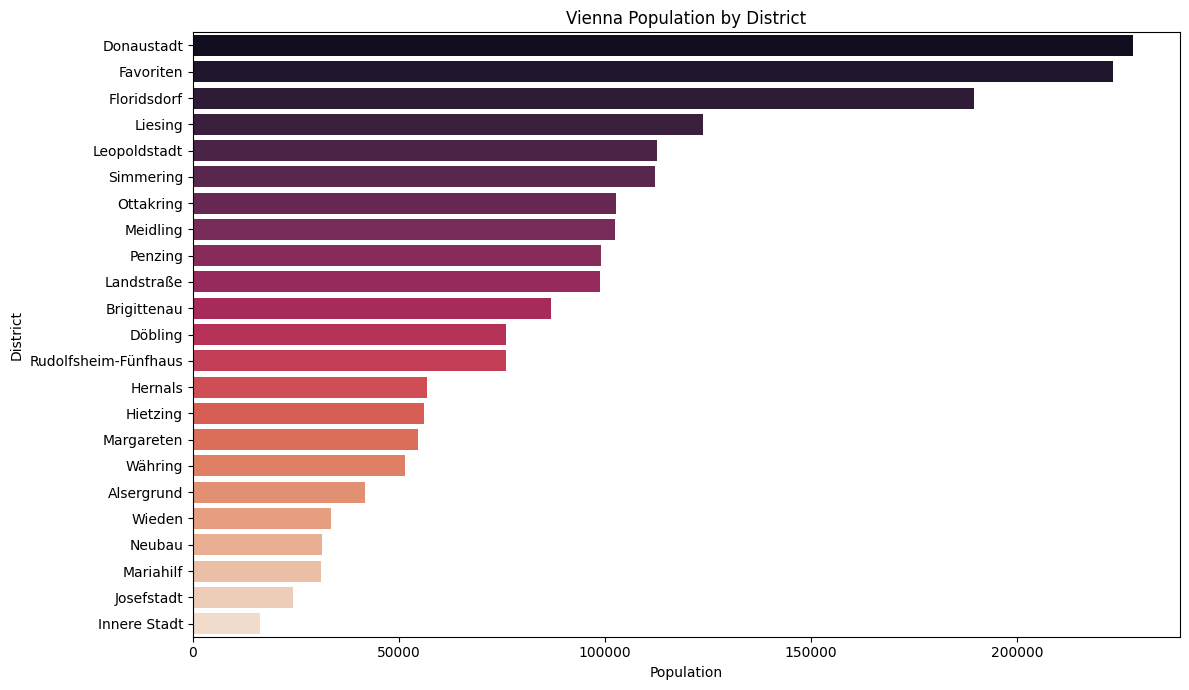

In [13]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=df,
    x="population",
    y="District",
    hue="District",
    palette="rocket",
    legend=False
)

plt.title("Vienna Population by District")
plt.xlabel("Population")
plt.ylabel("District")
plt.tight_layout()
plt.show()

Donaustadt (228,158) and Favoriten (223,190) had the largest populations. Not generally the ones with most density, we will investigate this while analysing the pharmacy dataset

In [20]:
# 2025 densities per distict scrapped form Statatlas

density = pd.DataFrame({
    "District": [
        "Margareten",
        "Josefstadt",
        "Mariahilf",
        "Neubau",
        "Rudolfsheim-Fünfhaus",
        "Wieden",
        "Brigittenau",
        "Alsergrund",
        "Landstraße",
        "Meidling",
        "Ottakring",
        "Währing",
        "Favoriten",
        "Leopoldstadt",
        "Innere Stadt",
        "Hernals",
        "Simmering",
        "Floridsdorf",
        "Liesing",
        "Döbling",
        "Penzing",
        "Donaustadt",
        "Hietzing"
    ],
    "density": [
        27128,
        22240,
        21363,
        19484,
        19373,
        18831,
        15228,
        14000,
        13357,
        12636,
        11844,
        8095,
        7013,
        5856,
        5675,
        4981,
        4822,
        4265,
        3859,
        3050,
        2934,
        2230,
        1488
    ]
})

final_df = density.merge(
    df,
    on="District",
    how="right"
)
final_df = final_df[["District", "population", "density"]]
final_df.head()

,District,population,density
0,Donaustadt,228158,2230
1,Favoriten,223190,7013
2,Floridsdorf,189551,4265
3,Liesing,123714,3859
4,Leopoldstadt,112675,5856


We will explore this density later in our pharamacies analysis

## Export the district-year table

In [21]:
final_df.to_csv("vienna_population_clean.csv", index=False)